# Task 2: Probability of rain in the next 30 minutes

**Group members:** (names and student IDs to be filled in)

| Name | Student ID |
|---|---|
| | |
| | |
| | |

**What this notebook does**
- **Question:** for a station, a time and a rainfall threshold, give the probability that the station collects more than that many mm in the next 30 minutes.
- **My part:** feature design, hyper-parameter tuning and model comparison.
- **Data:** the cleaned Parquet from the team's `data_preparation.ipynb`.
- **Models:** three Spark MLlib models (logistic regression, gradient-boosted trees, random forest).
- **Thresholds:** 0, 1, 2.5, 5 and 10 mm.
- **Split:** train on 2017 to 2022, tune and calibrate on 2023, test once on 2024.

**Terms used below**
- **Example:** one row of data for the model: one station at one moment, such as "S50 at 12:40 on 27 April".
- **Feature:** a fact the model is allowed to look at, such as the rain in the last 30 minutes or the hour of day.
- **Label:** the correct answer: 1 if the station really got more than the threshold in the next 30 minutes, otherwise 0.
- **PR-AUC:** how well the model ranks wet cases above dry ones. It matters because rain above 10 mm is rare, and a model could look good by always saying "no rain". It runs from 0 to 1, and higher is better.
- **Log loss, Brier score:** how good the probabilities are. Saying 80% and getting rain is good, and saying 80% and getting none is penalised. Lower is better.
- **Skill:** how much better the model is than climatology (the average for that station, hour and season). It is 1 − (model log loss ÷ climatology log loss). Zero means no better, and 0.5 means half the log loss.

**Computing environment**
- **Platform:** Google Cloud Dataproc, image `3.0-debian13`, Spark 4.1.2 on YARN, region `asia-southeast1`
- **Master:** 1 × `n1-highmem-2` (2 vCPU, about 13 GB memory, `spark.driver.memory=6g`)
- **Workers:** 2 × `n1-standard-4` (4 vCPU, 15 GB memory each)
- **Storage:** Google Cloud Storage bucket (raw CSV, cleaned Parquet, features, samples, models, results)
- **Notebook:** run from VS Code, connected to the cluster's Jupyter (PySpark kernel)

## 0. Settings and Spark

The next cell holds everything I might change, so a run can be repeated exactly:
- **Paths:** where the data and my results are stored.
- **Years:** train 2017 to 2022, validation 2023, test 2024.
- **Sample sizes:** the training sample is 5% of the data (`TRAIN_FRAC`). The full data is tens of millions of examples times five thresholds, which is too much to train on directly.
- **Validation and test:** 25% of 2023 and all of 2024. They are larger than the training share, so the final scores are less noisy.

In [1]:
import os, time, calendar
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pyspark import StorageLevel
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, GBTClassifier, RandomForestClassifier
from pyspark.ml.regression import IsotonicRegression, IsotonicRegressionModel
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

# ---------------------- EDIT THESE ----------------------
DATA = "gs://dsa5208-rainfall-kevin-data/parquet/"           # team's cleaned Parquet (your bucket)
WORK = "gs://dsa5208-rainfall-kevin-data/model"              # my outputs (on a Mac, use e.g. "/Users/you/.../model")
OUT  = "outputs"                                             # small files next to the notebook

TRAIN_YEARS, VAL_YEARS, TEST_YEARS = list(range(2017, 2023)), [2023], [2024]
THRESHOLDS = [0.0, 1.0, 2.5, 5.0, 10.0]                      # mm in the next 30 minutes
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.05, 0.25, 1.0       # larger run: 5% of training rows, 25% of 2023, all of 2024 (first quick test was 0.01, 0.05, 0.25)
TUNE_FRAC  = 0.1                                             # tuning uses this share of the training sample
N_NEIGHBOURS = 5
REDO_PREP = REDO_FEATURES = REDO_TUNING = REDO_MODELS = False
# --------------------------------------------------------

YEARS = TRAIN_YEARS + VAL_YEARS + TEST_YEARS
spark = SparkSession.builder.getOrCreate()
spark.conf.set("spark.sql.session.timeZone", "Asia/Singapore")
spark.conf.set("spark.sql.shuffle.partitions", "200")
spark.sparkContext.setLogLevel("ERROR")
os.makedirs(OUT, exist_ok=True)

# On the cluster the notebook's disk disappears when the cluster is deleted, so small result files
# (tables, figures) are copied to the bucket and copied back at the start of the next session.
def sync_up():
    if WORK.startswith("gs://"): os.system(f"gcloud storage cp -r {OUT}/* {WORK}/outputs/ > /dev/null 2>&1")
def sync_down():
    if WORK.startswith("gs://"): os.system(f"gcloud storage cp -r {WORK}/outputs/* {OUT}/ > /dev/null 2>&1")
sync_down()

def exists(p):                      # does a folder/file exist, on gs:// or on the local disk?
    path = spark._jvm.org.apache.hadoop.fs.Path(p)
    return path.getFileSystem(spark._jsc.hadoopConfiguration()).exists(path)

BLUE, GREY, ACCENT, GREEN, PURPLE = "#2a78d6", "#8a8f98", "#d9822b", "#5a9f6e", "#7a5cb8"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)
print("Spark", spark.version, "| master", spark.sparkContext.master)

Spark 4.1.2 | master yarn


## 1. Load the team's Parquet

In [2]:
raw = spark.read.parquet(DATA)
raw.printSchema()
print("rows:", f"{raw.count():,}", "| stations:", raw.select("station_id").distinct().count())

root
 |-- station_id: string (nullable = true)
 |-- date: date (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- update_timestamp: timestamp (nullable = true)
 |-- station_name: string (nullable = true)
 |-- station_device_id: string (nullable = true)
 |-- location_longitude: double (nullable = true)
 |-- location_latitude: double (nullable = true)
 |-- reading_update_timestamp: timestamp (nullable = true)
 |-- reading_value: double (nullable = true)
 |-- reading_type: string (nullable = true)
 |-- reading_unit: string (nullable = true)
 |-- station_name_clean: string (nullable = true)



rows: 48,538,713 | stations: 91


48,538,713 rows and 91 stations, the same as in the team's notebook, so I'm working on the right data.

## 2. Prepare the data

The features look back and forward by minutes, so every reading has to sit on a regular 5-minute grid. What I did:
- **Rounded each time to the nearest 5 minutes.** Some 2017 rows are stamped `:59`.
- **Kept the larger value** if two rows landed in the same slot, so no rain is lost.
- **Gave each station one position (the median).** S113 has two coordinates about 39 m apart.

I also flag rows I don't trust, without deleting them (`use_for_model = False`):
- **Outage days:** the whole network sent under 60% of its usual readings.
- **Partial station-days:** the station has fewer than 200 of 288 slots.

In [3]:
PREP = f"{WORK}/prepared"
OUTAGE_RATIO, MIN_SLOTS = 0.6, 200

if exists(f"{PREP}/_SUCCESS") and not REDO_PREP:
    print("prepared data exists, skipping")
else:
    d = raw.select("station_id", F.col("location_latitude").alias("lat"), F.col("location_longitude").alias("lon"),
                   F.col("timestamp").alias("ts"), F.col("reading_value").alias("rain_mm"))
    d = d.withColumn("ts5", F.to_timestamp(F.round(F.col("ts").cast("long") / 300) * 300))      # snap to 5 min

    pos = (d.groupBy("station_id").agg(F.expr("percentile_approx(lat, 0.5)").alias("lat"),
                                       F.expr("percentile_approx(lon, 0.5)").alias("lon")))     # one position per station
    d = (d.groupBy("station_id", "ts5").agg(F.max("rain_mm").alias("rain_mm"))                   # one row per slot
           .join(pos, "station_id")
           .withColumn("day", F.to_date("ts5")).withColumn("year", F.year("ts5")))

    day_rows = d.groupBy("year", "day").agg(F.count("*").alias("day_rows"))
    typical = day_rows.groupBy("year").agg(F.expr("percentile_approx(day_rows, 0.5)").alias("typical"))
    outage = (day_rows.join(typical, "year").filter(F.col("day_rows") < OUTAGE_RATIO * F.col("typical")).select("day").withColumn("outage_day", F.lit(True)))
    sd = d.groupBy("station_id", "day").agg(F.count("*").alias("station_day_slots"))

    d = (d.join(outage, "day", "left").join(sd, ["station_id", "day"])
           .withColumn("use_for_model", F.col("outage_day").isNull() & (F.col("station_day_slots") >= MIN_SLOTS))
           .select("station_id", "ts5", "lat", "lon", "rain_mm", "use_for_model", "year"))
    d.write.mode("overwrite").partitionBy("year").parquet(PREP)

prep = spark.read.parquet(PREP)
q = prep.agg(F.count("*").alias("rows"), F.sum((~F.col("use_for_model")).cast("int")).alias("flagged")).first()
print(f"rows after snapping and de-duplicating: {q['rows']:,} | marked not usable: {q['flagged']:,} ({q['flagged']/q['rows']:.2%})")

prepared data exists, skipping


rows after snapping and de-duplicating: 48,538,627 | marked not usable: 862,646 (1.78%)


The rules flag 1.78% of rows. They don't catch dead sensors, isolated spikes or a few faulty gauges, which my separate audit found; I list this under the limits.

## 3. Features

A feature is a fact the model gets to look at when it makes a prediction. Every feature here describes the situation at the prediction time *t*, using only the past. Nothing from after *t* is used.

**1. Own rain: has it been raining at this station?**
- `r0`: rain in the latest 5-minute reading, the one stamped *t*.
- `r15`, `r30`, `r60`: total rain in the last 15, 30 and 60 minutes. Rain that has lasted a while usually keeps going, so these are the most useful clues.
- `mx30`: the biggest single 5-minute reading in the last 30 minutes. It separates a steady drizzle from one sudden burst, even when the totals look the same.
- `mins_since_rain`: how many minutes since the station last measured any rain, capped at 360. A long dry spell means a low chance of rain.

**2. Neighbours: has it been raining nearby?**
Rain moves across the island, so I use the 5 nearest stations (the nearest is 1.7 km away at the median, the fifth 3.6 km).
- `nbr_n`: how many of the 5 neighbours had a complete last half hour of readings at that time.
- `nbr_r0_mean`, `nbr_r15_mean`, `nbr_r30_mean`: the average rain at the neighbours over the latest reading, the last 15 minutes and the last 30 minutes.
- `nbr_r30_max`: the largest 30-minute total among the neighbours.
- `nbr_wet15_n`: how many neighbours had rain in the last 15 minutes. If three of five are wet, a storm is probably close.

**3. Time and place: when and where?**
- `hour_sin`, `hour_cos`: the hour of day written as a position on a circle, so 23:55 sits right next to 00:00. If I used the plain number 0 to 24, the model would treat midnight and 11 pm as far apart.
- `doy_sin`, `doy_cos`: the same trick for the day of the year, so 31 December sits next to 1 January. This captures the monsoon seasons.
- `lat`, `lon`: the station's position, because some parts of the island are wetter than others.

**4. Threshold: how much rain are we asking about?**
- `thr`: the threshold itself (0, 1, 2.5, 5 or 10 mm). The same weather makes "more than 1 mm" likely and "more than 10 mm" unlikely, so the model must know which question it is answering.
- `log_thr`: the same number on a log scale, so the gaps between thresholds look more even.
- `r30_over_thr`: the last 30 minutes of rain divided by (threshold + 0.2). It says how close recent rain already is to

In [4]:
stations = (prep.select("station_id", "lat", "lon").distinct().toPandas())

def haversine(lat1, lon1, lat2, lon2):                       # distance in km between two points
    p = np.pi / 180
    a = np.sin((lat2 - lat1) * p / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2
    return 12742 * np.arcsin(np.sqrt(a))

rows = []
for _, a in stations.iterrows():
    dist = haversine(a["lat"], a["lon"], stations["lat"].values, stations["lon"].values)
    for j in np.argsort(dist)[1:N_NEIGHBOURS + 1]:           # [0] is the station itself
        rows.append((a["station_id"], stations.iloc[j]["station_id"], float(dist[j])))
nbr_map = pd.DataFrame(rows, columns=["station_id", "nbr_id", "km"])
print("distance to the nearest neighbour (median, km):", round(float(nbr_map.groupby("station_id")["km"].min().median()), 2),
      "| to the 5th nearest:", round(float(nbr_map.groupby("station_id")["km"].max().median()), 2))
nbr_sp = spark.createDataFrame(nbr_map[["station_id", "nbr_id"]])

distance to the nearest neighbour (median, km): 1.71 | to the 5th nearest: 3.64


In [5]:
FEAT = f"{WORK}/features"

def build_features(y):
    base = (spark.read.parquet(f"{PREP}/year={y}").filter("use_for_model")
              .select("station_id", "ts5", "lat", "lon", F.col("rain_mm").alias("r"), F.unix_timestamp("ts5").alias("t")))
    w = Window.partitionBy("station_id").orderBy("t")
    wr = lambda a, b: w.rangeBetween(a, b)                   # window in seconds relative to t
    d = (base
         .withColumn("n15", F.count("r").over(wr(-600, 0)))      # readings in the last 15 min (3 expected)
         .withColumn("n30", F.count("r").over(wr(-1500, 0)))     # last 30 min (6 expected)
         .withColumn("n60", F.count("r").over(wr(-3300, 0)))     # last 60 min (12 expected)
         .withColumn("r15", F.sum("r").over(wr(-600, 0)))
         .withColumn("r30", F.sum("r").over(wr(-1500, 0)))
         .withColumn("r60", F.sum("r").over(wr(-3300, 0)))
         .withColumn("mx30", F.max("r").over(wr(-1500, 0)))
         .withColumn("nf", F.count("r").over(wr(300, 1800)))     # next 30 min, AFTER t (6 expected)
         .withColumn("y30", F.sum("r").over(wr(300, 1800)))      # the label source
         .withColumn("last_wet", F.last(F.when(F.col("r") > 0, F.col("t")), True).over(w.rowsBetween(Window.unboundedPreceding, 0))))
    d = d.withColumn("mins_since_rain", F.coalesce(F.least(F.lit(360.0), (F.col("t") - F.col("last_wet")) / 60.0), F.lit(360.0)))
    d = d.withColumnRenamed("r", "r0")

    # neighbours: what the 5 nearest stations measured at the same time
    src = (d.filter(F.col("n30") == 6).select(F.col("station_id").alias("nbr_id"), "ts5",
             F.col("r0").alias("n_r0"), F.col("r15").alias("n_r15"), F.col("r30").alias("n_r30")))
    nb = (d.select("station_id", "ts5").join(F.broadcast(nbr_sp), "station_id").join(src, ["nbr_id", "ts5"])
            .groupBy("station_id", "ts5")
            .agg(F.count("*").alias("nbr_n"), F.avg("n_r0").alias("nbr_r0_mean"), F.avg("n_r15").alias("nbr_r15_mean"),
                 F.avg("n_r30").alias("nbr_r30_mean"), F.max("n_r30").alias("nbr_r30_max"), F.max("n_r0").alias("nbr_r0_max"),
                 F.sum((F.col("n_r15") > 0).cast("int")).alias("nbr_wet15_n")))

    f = d.filter((F.col("n60") == 12) & (F.col("nf") == 6)).join(nb, ["station_id", "ts5"], "left")
    for c in ["nbr_n", "nbr_r0_mean", "nbr_r15_mean", "nbr_r30_mean", "nbr_r30_max", "nbr_r0_max", "nbr_wet15_n"]:
        f = f.withColumn(c, F.coalesce(F.col(c), F.lit(0.0)))
    hr = F.hour("ts5") + F.minute("ts5") / 60.0
    f = (f.withColumn("hour_sin", F.sin(2 * np.pi * hr / 24)).withColumn("hour_cos", F.cos(2 * np.pi * hr / 24))
          .withColumn("doy_sin", F.sin(2 * np.pi * F.dayofyear("ts5") / 365.25)).withColumn("doy_cos", F.cos(2 * np.pi * F.dayofyear("ts5") / 365.25))
          .withColumn("hour", F.hour("ts5")).withColumn("month", F.month("ts5"))
          .withColumn("trend15", 2 * F.col("r15") - F.col("r30"))
          .withColumn("nbr_wet_share", F.when(F.col("nbr_n") > 0, F.col("nbr_wet15_n") / F.col("nbr_n")).otherwise(0.0)))
    cols = ["station_id", "ts5", "hour", "month", "lat", "lon", "hour_sin", "hour_cos", "doy_sin", "doy_cos",
            "r0", "r15", "r30", "r60", "mx30", "mins_since_rain",
            "nbr_n", "nbr_r0_mean", "nbr_r15_mean", "nbr_r30_mean", "nbr_r30_max", "nbr_wet15_n",
            "trend15", "nbr_r0_max", "nbr_wet_share", "y30"]
    f.select(*cols).write.mode("overwrite").parquet(f"{FEAT}/year={y}")

for y in YEARS:
    if exists(f"{FEAT}/year={y}/_SUCCESS") and not REDO_FEATURES:
        print(f"{y}: features exist, skipping"); continue
    t0 = time.time(); build_features(y)
    print(f"{y}: done in {time.time()-t0:.0f}s")
feat = spark.read.parquet(FEAT)
print("examples:", f"{feat.count():,}")

2017: features exist, skipping
2018: features exist, skipping
2019: features exist, skipping
2020: features exist, skipping
2021: features exist, skipping
2022: features exist, skipping
2023: features exist, skipping
2024: features exist, skipping


examples: 46,430,730


46,430,730 examples, a bit fewer than the prepared rows because examples near gaps and day edges are dropped on purpose.

### Leakage check

Leakage means the model sees information from the future, which would make every score look better than it really is. A common cause is a time window that is off by one slot, so I tested the features by hand.

**What the check does**
- It picks 5 random examples from 2024.
- For each one, it reads that station's raw readings with pandas, separately from the Spark pipeline.
- It adds up the 6 readings up to and including the prediction time *t*, which is the last 30 minutes. This should equal `r30`.
- It adds up the 6 readings after *t* (+5 to +30 minutes). This should equal `y30`, the amount the label is made from.
- It also prints the time the future window starts, which should be exactly 5 minutes after *t*.
- If any example doesn't match, the cell stops with an error.

**Result:** all five match, and every future window starts exactly 5 minutes after *t*. So the features look only backwards and the label looks only forwards.

In [6]:
yy = TEST_YEARS[0] if TEST_YEARS[0] in YEARS else YEARS[-1]
samp = feat.filter(F.col("year") == yy).orderBy(F.rand(7)).limit(5).toPandas()
ok_all = True
for r in samp.itertuples():
    s = (spark.read.parquet(f"{PREP}/year={yy}").filter((F.col("station_id") == r.station_id) & F.col("use_for_model"))
         .select("ts5", "rain_mm").toPandas().set_index("ts5")["rain_mm"].sort_index())
    t = pd.Timestamp(r.ts5)
    past30 = s[(s.index > t - pd.Timedelta(minutes=30)) & (s.index <= t)]        # 6 slots ending at t
    fut30  = s[(s.index > t) & (s.index <= t + pd.Timedelta(minutes=30))]        # 6 slots AFTER t
    ok = (len(past30) == 6 and len(fut30) == 6 and abs(past30.sum() - r.r30) < 1e-6 and abs(fut30.sum() - r.y30) < 1e-6)
    ok_all &= ok
    print(f"{r.station_id} {t}:  r30 {r.r30:.2f} vs {past30.sum():.2f} | y30 {r.y30:.2f} vs {fut30.sum():.2f} | future starts {fut30.index.min()} -> {'OK' if ok else 'MISMATCH'}")
assert ok_all, "feature or label check failed"

26/10/11 14:07:03 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


S116 2024-01-10 21:15:00:  r30 0.00 vs 0.00 | y30 0.00 vs 0.00 | future starts 2024-01-10 21:20:00 -> OK


S112 2024-01-25 00:45:00:  r30 0.00 vs 0.00 | y30 0.60 vs 0.60 | future starts 2024-01-25 00:50:00 -> OK
S209 2024-08-01 13:45:00:  r30 0.00 vs 0.00 | y30 0.00 vs 0.00 | future starts 2024-08-01 13:50:00 -> OK


S216 2024-02-06 20:10:00:  r30 0.00 vs 0.00 | y30 0.00 vs 0.00 | future starts 2024-02-06 20:15:00 -> OK
S33 2024-11-10 15:35:00:  r30 0.00 vs 0.00 | y30 0.00 vs 0.00 | future starts 2024-11-10 15:40:00 -> OK


All five match, and the future window starts exactly five minutes after the prediction time.

## 4. Splits, samples and thresholds

**The split (by time, not at random)**
- **Train:** 2017 to 2022. The model learns from these years.
- **Validation:** 2023. I use it to tune settings, choose between models and fit the calibrators.
- **Test:** 2024. It is used once at the end, for the final score.
- **Why not a random split:** a storm lasts hours, so a random split would put minutes from the same storm in both the training and test sets. The model would then have seen the answer and the scores would look too good. Splitting by time is also closer to real use, where we predict a future we haven't seen.

**The samples**
- The full data is too large to train on directly, so each period uses a sample (5% of training, 25% of 2023, all of 2024).
- The sample is chosen with a fixed hash of station and time, so every run picks exactly the same rows.
- It is uniform, so the share of rainy examples in the sample stays the same as in the real data. A sample that favoured wet times would make rain look more common than it is.

**One row per threshold**
- Each example is repeated 5 times, once for each threshold (0, 1, 2.5, 5, 10 mm).
- Each copy has its own label: 1 if the next 30 minutes were above that threshold, otherwise 0.
- The threshold becomes an input, so one model answers any threshold, as the task asks, instead of five separate models.

In [7]:
SAMPLE_TAG = f"{TRAIN_FRAC}_{VAL_FRAC}_{TEST_FRAC}"

def pick(years, frac):
    df = feat.filter(F.col("year").isin(years))
    return df.filter(F.abs(F.hash("station_id", "ts5")) % 100000 < int(frac * 100000))

def expand(df):
    thr = F.explode(F.array(*[F.lit(float(t)) for t in THRESHOLDS]))
    return (df.withColumn("thr", thr).withColumn("label", (F.col("y30") > F.col("thr")).cast("double"))
              .withColumn("log_thr", F.log1p("thr"))
              .withColumn("r30_over_thr", F.col("r30") / (F.col("thr") + 0.2))
              .withColumn("nbr30_over_thr", F.col("nbr_r30_mean") / (F.col("thr") + 0.2))
              .withColumn("season", F.when(F.col("month").isin(12, 1, 2, 3), 1).when(F.col("month").isin(4, 5), 2)
                                     .when(F.col("month").isin(6, 7, 8, 9), 3).otherwise(4)))

S = {}
for name, (yrs, frac) in {"train": (TRAIN_YEARS, TRAIN_FRAC), "val": (VAL_YEARS, VAL_FRAC), "test": (TEST_YEARS, TEST_FRAC)}.items():
    p = f"{WORK}/samples/{SAMPLE_TAG}/{name}"
    if not (exists(f"{p}/_SUCCESS") and not REDO_FEATURES):
        pick(yrs, frac).write.mode("overwrite").parquet(p)
    S[name] = spark.read.parquet(p)
    print(f"{name:5s}: years {yrs[0]}-{yrs[-1]}, {S[name].count():,} examples (x {len(THRESHOLDS)} thresholds)")

tr0 = expand(S["train"])
rate = tr0.groupBy("thr").agg(F.avg("label").alias("rate"), F.count("*").alias("n")).orderBy("thr").toPandas()
rate["positives"] = (rate["rate"] * rate["n"]).round().astype(int)
rate["yes_%"] = (rate["rate"] * 100).round(3)
display(rate[["thr", "yes_%", "positives", "n"]])
POS_RATE = dict(zip(rate["thr"], rate["rate"]))

train: years 2017-2022, 1,675,727 examples (x 5 thresholds)


val  : years 2023-2023, 1,663,625 examples (x 5 thresholds)


test : years 2024-2024, 6,279,352 examples (x 5 thresholds)


,thr,yes_%,positives,n
0,0.0,6.032,101074,1675727
1,1.0,2.336,39141,1675727
2,2.5,1.354,22687,1675727
3,5.0,0.806,13514,1675727
4,10.0,0.385,6449,1675727


Rain is rare, and the higher the threshold, the rarer it gets. In the training sample, the share of "yes" examples is:

| Threshold | "Yes" share | Number of "yes" examples |
|---|---|---|
| more than 0 mm | 6.03% | 101,074 |
| more than 1 mm | 2.34% | 39,141 |
| more than 2.5 mm | 1.35% | 22,687 |
| more than 5 mm | 0.81% | 13,514 |
| more than 10 mm | 0.39% | 6,449 |

This is the class imbalance problem:
- **Accuracy would be misleading.** A model that always answers "no rain" would be 99.6% accurate at 10 mm and still useless.
- **So I use other scores.** PR-AUC checks how well the model ranks the rare wet cases above the dry ones. Log loss and Brier score check the probabilities themselves.
- **Class weights.** I also give "yes" examples more weight during training (capped at 20 times), so the model doesn't learn to ignore rare rain. That is why the raw probabilities need calibrating later.

## 5. Baselines

A model is only useful if it beats simple rules, so I built two baselines to compare against. Both use only the training years.

**Climatology: the usual weather for that place and time**
- It uses the share of "yes" for the same station, the same hour of day and the same season.
- Example: if a station is usually wet at 4 pm in the monsoon season, climatology predicts a higher chance then.
- It ignores what is happening right now.
- Small groups are smoothed towards the overall average, so a group with only a few examples doesn't give an extreme chance like 0% or 100%.

**Persistence: assume the current weather continues**
- It uses the share of "yes" after rain in the last 30 minutes, and the share after a dry half hour.
- That gives one number for "it just rained" and one for "it was dry".
- It ignores the station, the time and the neighbours.

**Why both:** climatology knows the normal pattern but not today's weather. Persistence knows today's weather but not the normal pattern. A good model should beat both.

In [8]:
SMOOTH = 20.0
tr = tr0.withColumn("wet30", (F.col("r30") > 0).cast("int"))
overall = spark.createDataFrame(pd.DataFrame({"thr": list(POS_RATE), "p_all": list(POS_RATE.values())}))
clim = (tr.groupBy("thr", "station_id", "hour", "season").agg(F.sum("label").alias("pos"), F.count("*").alias("n"))
          .join(overall, "thr").withColumn("p_clim", (F.col("pos") + SMOOTH * F.col("p_all")) / (F.col("n") + SMOOTH))
          .select("thr", "station_id", "hour", "season", "p_clim"))
pers = tr.groupBy("thr", "wet30").agg(F.avg("label").alias("p_pers"))
clim.cache(); print("climatology groups:", clim.count())
display(pers.orderBy("thr", "wet30").toPandas().pivot(index="thr", columns="wet30", values="p_pers")
        .rename(columns={0: "P(yes | dry last 30 min)", 1: "P(yes | rain in last 30 min)"}).round(4))
clim_any = (tr0.filter(F.col("thr") == THRESHOLDS[0]).groupBy("station_id", "hour", "season").agg(F.avg("label").alias("clim_any")))

climatology groups: 41155


wet30,P(yes | dry last 30 min),P(yes | rain in last 30 min)
thr,,
0.0,0.0239,0.6305
1.0,0.0075,0.2708
2.5,0.0047,0.1521
5.0,0.0027,0.0921
10.0,0.0011,0.0462


**What the output shows.** Rain in the last 30 minutes changes the chance of rain a lot:

| Threshold | Chance of "yes" after a dry half hour | Chance of "yes" after rain in the last 30 min |
|---|---|---|
| more than 0 mm | 2.4% | 63.1% |
| more than 1 mm | 0.8% | 27.1% |
| more than 2.5 mm | 0.5% | 15.2% |
| more than 5 mm | 0.3% | 9.2% |
| more than 10 mm | 0.1% | 4.6% |

- After rain, the chance is roughly 25 to 40 times higher than after a dry half hour. So the recent past is a strong clue.
- That makes persistence the harder baseline to beat at a 30-minute horizon. The test results in section 8 confirm this: at more than 0 mm, persistence scores 0.52 PR-AUC against 0.11 for climatology.
- The baselines also show a ceiling for each rule. Even after rain, a heavy 10 mm burst is only 4.6% likely, so a model needs more than "it just rained" to do well.

## 6. Feature groups, tuning and ablation

This is the part I own: which features matter, and which model settings work best.

**Class weights**
- A "yes" example counts more in training when its threshold is rare, so the model doesn't learn to ignore rare rain.
- The weight is (1 − p) ÷ p, where p is the share of "yes" for that threshold, capped at 20.
- In the output, the 0 mm threshold gets a weight of 15.6, and the other four thresholds all hit the cap of 20.

**Feature groups (25 numeric features, plus the station ID)**

- **`time_place` (6):** `lat`, `lon` (the station's position), `hour_sin`, `hour_cos` (time of day on a circle), `doy_sin`, `doy_cos` (day of the year on a circle).
- **`own_rain` (6):** `r0` (latest 5-minute reading), `r15`, `r30`, `r60` (rain in the last 15, 30 and 60 minutes), `mx30` (biggest 5-minute reading in the last 30 minutes), `mins_since_rain`.
- **`neighbours` (6):** `nbr_n` (how many neighbours reported), `nbr_r0_mean`, `nbr_r15_mean`, `nbr_r30_mean` (average rain at the neighbours), `nbr_r30_max` (largest 30-minute total among them), `nbr_wet15_n` (how many were wet in the last 15 minutes).
- **`threshold` (4):** `thr` (the threshold), `log_thr` (the same on a log scale), `r30_over_thr`, `nbr30_over_thr` (recent rain divided by the threshold, for the station and for its neighbours).
- **`new_ideas` (3):** my own features: `trend15` (rising or fading rain), `nbr_r0_max` (biggest neighbour reading now), `nbr_wet_share` (share of neighbours that are wet).
- The station ID is also given to the model as a category, so it can learn that some stations are wetter than others.
- A sixth group, `history_rate` (the climatology rate, `clim_any`), was dropped after a first run showed no gain (see 6.4).

**What is an ablation?**
- An ablation is a test where you remove one part of the model and see how much worse it gets.
- Here the parts are the feature groups. I retrain the model once with everything, and then once more for each group, with that group left out.
- I compare the scores. If the score drops a lot without a group, the model really relies on it. If the score hardly changes, the group adds little. If the score goes up, the group was adding noise.
- It answers "which of my features actually matter?" with evidence, instead of guessing.
- The threshold group is never removed, because the threshold has to be an input for the model to answer the question.

**The three data sets used here**
- **Training sample:** 8,378,635 rows (1,675,727 examples × 5 thresholds).
- **Tuning sample:** 835,950 rows, which is 10% of the training sample. Each trial takes minutes instead of tens of minutes.
- **Validation:** 8,318,125 rows (the 2023 sample).

In [9]:
GROUPS = {
    "time_place":   ["lat", "lon", "hour_sin", "hour_cos", "doy_sin", "doy_cos"],
    "own_rain":     ["r0", "r15", "r30", "r60", "mx30", "mins_since_rain"],
    "neighbours":   ["nbr_n", "nbr_r0_mean", "nbr_r15_mean", "nbr_r30_mean", "nbr_r30_max", "nbr_wet15_n"],
    "history_rate": ["clim_any"],
    "threshold":    ["thr", "log_thr", "r30_over_thr", "nbr30_over_thr"],
    "new_ideas":    ["trend15", "nbr_r0_max", "nbr_wet_share"],
}
DROP_GROUPS = ["history_rate"]     # the first ablation showed no gain from this group; remove it from the final model
for g in DROP_GROUPS: GROUPS.pop(g, None)
NUM = [c for g in GROUPS.values() for c in g]

POS_W = {t: float(min(20.0, (1 - p) / max(p, 1e-6))) for t, p in POS_RATE.items()}
print("weight of a 'yes' example, by threshold:", {k: round(v, 1) for k, v in POS_W.items()})
wmap = F.create_map(*sum([[F.lit(k), F.lit(v)] for k, v in POS_W.items()], []))

def prep_set(name):
    d = expand(S[name]).join(F.broadcast(clim_any), ["station_id", "hour", "season"], "left")
    d = d.withColumn("clim_any", F.coalesce(F.col("clim_any"), F.lit(POS_RATE[THRESHOLDS[0]])))
    return d.withColumn("w", F.when(F.col("label") == 1.0, wmap[F.col("thr")]).otherwise(F.lit(1.0)))

train = prep_set("train").persist(StorageLevel.MEMORY_AND_DISK)
val   = prep_set("val").persist(StorageLevel.MEMORY_AND_DISK)
tune  = train.filter(F.abs(F.hash("ts5", "station_id")) % 1000 < int(TUNE_FRAC * 1000)).persist(StorageLevel.MEMORY_AND_DISK)
print(f"train {train.count():,} | tune {tune.count():,} | validation {val.count():,} rows")

weight of a 'yes' example, by threshold: {0.0: 15.6, 1.0: 20.0, 2.5: 20.0, 5.0: 20.0, 10.0: 20.0}


train 8,378,635 | tune 835,950 | validation 8,318,125 rows


### 6.2 Training and scoring one model

Tuning means trying many settings, so I wrote the training and scoring steps as functions. Every trial then runs in exactly the same way, and only the settings change.

**`make_pipeline`: builds one model from a name, its settings and a list of features**
- The station ID is turned into a number (`StringIndexer`).
- **Logistic regression:** the station is one-hot encoded (one yes/no column per station), and all features are scaled to a similar size, because logistic regression is sensitive to scale.
- **Gradient-boosted trees and random forest:** the station number is used directly, and no scaling is needed, because trees only compare values.
- Every model uses the class weights from 6.1 (`weightCol`).

**`score`:** runs a fitted model on a data set and returns the predicted probability of "yes" for each row.

**`val_pr_auc`:** the number I use to compare trials.
- It scores the model on the validation year (2023), separately for each of the five thresholds.
- It then averages the five PR-AUC values into one number.
- I chose PR-AUC because it depends only on how the model ranks cases, not on the probabilities themselves. The class weights push the raw probabilities up, so a score based on the probabilities would be distorted.

In [10]:
def make_pipeline(kind, params, cols):
    idx = StringIndexer(inputCol="station_id", outputCol="station_idx", handleInvalid="keep")
    if kind == "lr":
        ohe = OneHotEncoder(inputCols=["station_idx"], outputCols=["station_ohe"], handleInvalid="keep")
        asm = VectorAssembler(inputCols=cols + ["station_ohe"], outputCol="raw", handleInvalid="keep")
        sc = StandardScaler(inputCol="raw", outputCol="features", withMean=False, withStd=True)
        clf = LogisticRegression(featuresCol="features", labelCol="label", weightCol="w", maxIter=60, regParam=params["regParam"])
        return Pipeline(stages=[idx, ohe, asm, sc, clf])
    asm = VectorAssembler(inputCols=["station_idx"] + cols, outputCol="features", handleInvalid="keep")
    if kind == "gbt":
        clf = GBTClassifier(featuresCol="features", labelCol="label", weightCol="w", maxIter=params["maxIter"],
                            maxDepth=params["maxDepth"], maxBins=128, stepSize=0.1, subsamplingRate=0.8, seed=1)
    else:
        clf = RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="w", numTrees=params["numTrees"],
                                     maxDepth=params["maxDepth"], maxBins=128, subsamplingRate=0.7, seed=1)
    return Pipeline(stages=[idx, asm, clf])

def score(model, df):
    keep = ["station_id", "ts5", "hour", "season", "thr"] + (["label"] if "label" in df.columns else [])
    return model.transform(df).select(*keep, vector_to_array("probability")[1].alias("p"))

def val_pr_auc(model, df=None):
    df = val if df is None else df
    out = {}
    for t in THRESHOLDS:
        s = score(model, df.filter(F.col("thr") == t))
        out[t] = BinaryClassificationEvaluator(rawPredictionCol="p", labelCol="label", metricName="areaUnderPR").evaluate(s)
    out["mean"] = float(np.mean([out[t] for t in THRESHOLDS]))
    return out

### 6.3 Hyper-parameter search

A hyper-parameter is a setting chosen before training, such as how deep the trees are. The right values change the result a lot, so I tried a small grid for each model (13 trials in total):

- **Logistic regression (3 trials):** the penalty strength `regParam` = 1e-5, 1e-4 or 1e-3. A bigger penalty stops the model from relying too much on any one feature.
- **Gradient-boosted trees (6 trials):** tree depth 3, 5 or 7, each with 30 or 60 rounds. This model builds many small trees one after another, and each tree corrects the mistakes of the last. A round is one tree.
- **Random forest (4 trials):** 40 or 80 trees, each with depth 8 or 12. This model builds many deep trees independently and lets them vote.

How I compared them:
- Each setting is trained on the tuning sample and scored on the validation year (2023) with the mean PR-AUC from 6.2. The best setting for each model is kept.
- I did not use `CrossValidator`. It splits the data into random folds, so minutes from the same storm would sit in both the training and validation parts and leak. A time-ordered validation year avoids that.

In [11]:
GRID = {
    "lr":  [dict(regParam=r) for r in (1e-5, 1e-4, 1e-3)],
    "gbt": [dict(maxDepth=d, maxIter=i) for d in (3, 5, 7) for i in (30, 60)],
    "rf":  [dict(numTrees=n, maxDepth=d) for n in (40, 80) for d in (8, 12)],
}
TUNE_CSV = f"{OUT}/tuning_results_{SAMPLE_TAG}.csv"

if os.path.exists(TUNE_CSV) and not REDO_TUNING:
    tuning = pd.read_csv(TUNE_CSV); print("loaded saved tuning results")
else:
    recs = []
    for kind, settings in GRID.items():
        for p in settings:
            t0 = time.time()
            m = make_pipeline(kind, p, NUM).fit(tune)
            r = val_pr_auc(m)
            recs.append(dict(model=kind, params=str(p), mean_pr_auc=r["mean"], seconds=round(time.time() - t0),
                             **{f"pr_auc_{t:g}": r[t] for t in THRESHOLDS}))
            print(f"{kind:3s} {p}: mean PR-AUC {r['mean']:.4f} ({recs[-1]['seconds']}s)")
    tuning = pd.DataFrame(recs); tuning.to_csv(TUNE_CSV, index=False); sync_up()

display(tuning.sort_values(["model", "mean_pr_auc"], ascending=[True, False]).round(4))
BEST = {k: eval(g.sort_values("mean_pr_auc").iloc[-1]["params"]) for k, g in tuning.groupby("model")}
print("best settings:", BEST)

lr  {'regParam': 1e-05}: mean PR-AUC 0.5090 (140s)


lr  {'regParam': 0.0001}: mean PR-AUC 0.5089 (101s)


lr  {'regParam': 0.001}: mean PR-AUC 0.5074 (92s)


gbt {'maxDepth': 3, 'maxIter': 30}: mean PR-AUC 0.4712 (83s)


gbt {'maxDepth': 3, 'maxIter': 60}: mean PR-AUC 0.4906 (115s)


...

rf  {'numTrees': 80, 'maxDepth': 8}: mean PR-AUC 0.5237 (128s)


26/10/11 14:36:58 WARN DAGScheduler: Broadcasting large task binary with size 1031.1 KiB
26/10/11 14:37:05 WARN DAGScheduler: Broadcasting large task binary with size 1981.0 KiB
26/10/11 14:37:15 WARN DAGScheduler: Broadcasting large task binary with size 3.5 MiB
26/10/11 14:37:26 WARN DAGScheduler: Broadcasting large task binary with size 6.0 MiB
26/10/11 14:37:40 WARN DAGScheduler: Broadcasting large task binary with size 9.6 MiB
26/10/11 14:37:53 WARN DAGScheduler: Broadcasting large task binary with size 1283.1 KiB
26/10/11 14:37:57 WARN DAGScheduler: Broadcasting large task binary with size 14.2 MiB
26/10/11 14:38:13 WARN DAGScheduler: Broadcasting large task binary with size 1684.7 KiB
26/10/11 14:38:18 WARN DAGScheduler: Broadcasting large task binary with size 20.0 MiB
26/10/11 14:38:36 WARN DAGScheduler: Broadcasting large task binary with size 2.0 MiB
26/10/11 14:38:44 WARN DAGScheduler: Broadcasting large task binary with size 15.4 MiB
26/10/11 14:39:11 WARN DAGScheduler: Br

rf  {'numTrees': 80, 'maxDepth': 12}: mean PR-AUC 0.5221 (260s)


,model,params,mean_pr_auc,seconds,pr_auc_0,pr_auc_1,pr_auc_2.5,pr_auc_5,pr_auc_10
6,gbt,"{'maxDepth': 5, 'maxIter': 60}",0.5107,167,0.7369,0.6149,0.5045,0.4207,0.2763
5,gbt,"{'maxDepth': 5, 'maxIter': 30}",0.5072,98,0.7358,0.6072,0.5037,0.4170,0.2724
4,gbt,"{'maxDepth': 3, 'maxIter': 60}",0.4906,115,0.7220,0.5902,0.4672,0.4062,0.2676
8,gbt,"{'maxDepth': 7, 'maxIter': 60}",0.4868,276,0.7258,0.6060,0.4825,0.3889,0.2307
7,gbt,"{'maxDepth': 7, 'maxIter': 30}",0.4815,131,0.7246,0.5977,0.4735,0.3838,0.2280
3,gbt,"{'maxDepth': 3, 'maxIter': 30}",0.4712,83,0.7155,0.5648,0.4448,0.3877,0.2430
0,lr,{'regParam': 1e-05},0.5090,140,0.7041,0.5901,0.4966,0.4333,0.3207
1,lr,{'regParam': 0.0001},0.5089,101,0.7053,0.5895,0.4960,0.4333,0.3206
2,lr,{'regParam': 0.001},0.5074,92,0.7104,0.5850,0.4918,0.4309,0.3186
11,rf,"{'numTrees': 80, 'maxDepth': 8}",0.5237,128,0.7440,0.6231,0.5194,0.4373,0.2945


best settings: {'gbt': {'maxDepth': 5, 'maxIter': 60}, 'lr': {'regParam': 1e-05}, 'rf': {'numTrees': 80, 'maxDepth': 8}}


**What the tuning table shows:**
- **Best settings:** gradient-boosted trees at depth 5 with 60 rounds (0.511), random forest with 80 trees at depth 8 (0.524), and logistic regression with `regParam` = 1e-5 (0.509).
- **Gradient-boosted trees:** depth 5 beat depth 7 (0.511 against 0.487), so the deeper trees were probably overfitting. 60 rounds beat 30 rounds at every depth, most clearly at depth 3.
- **Random forest:** 80 trees beat 40 trees, but depth made little difference (0.524 at depth 8 against 0.522 at depth 12 with 80 trees), so I chose the cheaper depth 8.
- **Logistic regression:** the penalty hardly mattered (0.509, 0.509 and 0.507).
- **Caveat:** tuning used a small sample, so the best settings may shift a little with more data.

### 6.4 Which feature groups matter?

An ablation removes one feature group at a time to see how much the score drops. This shows what the model really relies on, and whether my added features are worth keeping.

**What I did**
- I used the best gradient-boosted settings (depth 5), but with 30 rounds instead of 60.
- I trained on half of the tuning sample (417,755 rows).
- I trained 5 times: once with all features, then once without each of `time_place`, `own_rain`, `neighbours` and `new_ideas`.
- Each run is scored with the mean PR-AUC on the validation year, as in 6.2.
- The `threshold` group always stays in, because the threshold has to be an input.

**Why the lighter setting**
- My first attempt used the full tuning sample and took over 30 minutes without finishing, so I cut it down.
- The aim is to compare the groups with each other, not to get the best model, so a lighter model is enough.

ablation sample rows: 417,755 | settings: {'maxDepth': 5, 'maxIter': 30}


[1/5] without (none: all features): mean PR-AUC 0.4744 (83s)


[2/5] without time_place: mean PR-AUC 0.4730 (78s)


[3/5] without own_rain: mean PR-AUC 0.4573 (77s)


[4/5] without neighbours: mean PR-AUC 0.4721 (83s)


[5/5] without new_ideas: mean PR-AUC 0.4678 (81s)


,removed,mean_pr_auc,pr_auc_0,pr_auc_1,pr_auc_2.5,pr_auc_5,pr_auc_10,delta
0,(none: all features),0.4744,0.7245,0.5858,0.4722,0.3792,0.2105,0.0000
1,time_place,0.4730,0.7210,0.5847,0.4710,0.3765,0.2117,-0.0014
2,own_rain,0.4573,0.7060,0.5661,0.4488,0.3564,0.2093,-0.0171
3,neighbours,0.4721,0.7236,0.5862,0.4683,0.3725,0.2101,-0.0023
4,new_ideas,0.4678,0.7269,0.5836,0.4665,0.3651,0.1969,-0.0066


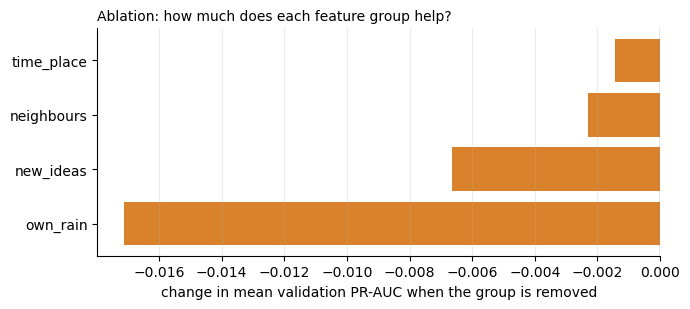

In [12]:
ABL_CSV = f"{OUT}/ablation_results_{SAMPLE_TAG}.csv"
ABL_ROUNDS = 30        # fewer rounds than the tuned setting: this is an importance check, not the final model
abl_params = dict(BEST["gbt"]); abl_params["maxIter"] = min(ABL_ROUNDS, abl_params["maxIter"])
abl_data = tune.filter(F.abs(F.hash("station_id", "ts5")) % 2 == 0).persist(StorageLevel.MEMORY_AND_DISK)   # half of the tuning sample
print("ablation sample rows:", f"{abl_data.count():,}", "| settings:", abl_params, flush=True)

if os.path.exists(ABL_CSV) and not REDO_TUNING:
    abl = pd.read_csv(ABL_CSV); print("loaded saved ablation")
else:
    runs = [("(none: all features)", NUM)] + [(g, [c for c in NUM if c not in cols_g]) for g, cols_g in GROUPS.items() if g != "threshold"]
    recs = []
    for i, (name, cols) in enumerate(runs, 1):
        t0 = time.time()
        r = val_pr_auc(make_pipeline("gbt", abl_params, cols).fit(abl_data))
        recs.append(dict(removed=name, mean_pr_auc=r["mean"], **{f"pr_auc_{t:g}": r[t] for t in THRESHOLDS}))
        print(f"[{i}/{len(runs)}] without {name}: mean PR-AUC {r['mean']:.4f} ({time.time()-t0:.0f}s)", flush=True)
    abl = pd.DataFrame(recs); abl.to_csv(ABL_CSV, index=False); sync_up()
abl["delta"] = abl["mean_pr_auc"] - abl["mean_pr_auc"].iloc[0]
display(abl.round(4))

fig, ax = plt.subplots(figsize=(7, 3.2))
a = abl.iloc[1:].sort_values("delta")
ax.barh(a["removed"], a["delta"], color=[ACCENT if v < 0 else GREEN for v in a["delta"]])
ax.axvline(0, color=GREY, lw=1); ax.set_xlabel("change in mean validation PR-AUC when the group is removed")
ax.set_title("Ablation: how much does each feature group help?", fontsize=10, loc="left"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(f"{OUT}/ablation.png", dpi=160, bbox_inches="tight"); sync_up(); plt.show()

**What the table shows**

Score with all features: 0.474 (mean PR-AUC on the validation year). Each row is the score with one group removed.

| Group removed | Score without it | Change | What it means |
|---|---|---|---|
| `own_rain` | 0.457 | −0.017 | The biggest drop. The model relies on the station's own recent rain. |
| `new_ideas` | 0.468 | −0.007 | A small drop, so my three added features help a little. |
| `neighbours` | 0.472 | −0.002 | Almost no change. |
| `time_place` | 0.473 | −0.001 | Almost no change. |

In simple words:
- **Most important:** the station's own recent rain. Without it, the score clearly falls.
- **Helpful:** my added features (`trend15`, `nbr_r0_max`, `nbr_wet_share`). Removing them costs a little.
- **Barely matter here:** `time_place` and `neighbours`. The score hardly moves without them.

**Caveat about neighbours**
- The ratio `nbr30_over_thr` (neighbour rain divided by the threshold) is in the `threshold` group, which is never removed.
- So removing the `neighbours` group still leaves some neighbour information in the model.
- The feature importance in section 8 ranks `nbr30_over_thr` first.
- So the table shows that the other neighbour features add little, not that neighbours don't matter.

**An earlier result:** in my first, smaller run, removing `history_rate` raised the score from 0.419 to 0.442, so I left it out of the final model.

### 6.5 Ideas I tried

- **My three added features** (`trend15`, `nbr_r0_max`, `nbr_wet_share`)
  - Idea: tell the model whether rain is rising or fading, and whether any neighbour is in heavy rain.
  - Result: the score is 0.474 with them and 0.468 without (ablation in 6.4), a small gain.
  - **Kept.**
- **`history_rate`** (how often this station is wet at this hour and season, as a feature)
  - Idea: give the model the usual weather pattern as a starting point.
  - Result: in my first, smaller run the score went up without it (0.419 to 0.442).
  - **Dropped.** The model already gets the time of day, the season and the station, so this was probably repeating what it knew.
- **Deeper trees** (depth 7 for gradient-boosted trees)
  - Idea: let the trees model more complicated patterns.
  - Result: the score was lower than at depth 5 (0.487 against 0.511 with 60 rounds).
  - **Not used.**

## 7. Final models and calibration

**Training**
- I trained the three models with their best settings from 6.3, on the whole training sample (8.4 million rows, which is 5% of the training years × 5 thresholds). Tuning used only a small part of it.
- The best settings are depth 5 with 60 rounds for gradient-boosted trees, 80 trees at depth 8 for the random forest, and `regParam` = 1e-5 for logistic regression.
- The models are saved, so they can be loaded again without retraining.

**Calibration**
- The class weights make the model say "rain" more often than it should, so its raw probabilities come out too high. The reliability plot in section 8 shows this: when the raw model predicts 80%, rain happens only about 15 to 20% of the time.
- Calibration fixes this. It learns a correction curve from the model's raw probability to the real frequency (isotonic regression: a curve that only goes up).
- I fitted one curve for each model and each threshold (15 in total) on the validation year.
- I never fitted them on 2024, so the test stays honest.

In [13]:
RUN_TAG = f"train{TRAIN_FRAC}_" + "_".join(f"{k}{'-'.join(str(v) for v in BEST[k].values())}" for k in ("lr", "gbt", "rf"))
print("run tag:", RUN_TAG)
NAMES = {"clim": "Climatology (baseline)", "pers": "Persistence (baseline)", "lr": "Logistic regression",
         "gbt": "Gradient-boosted trees", "rf": "Random forest"}

MODELS = {}
for kind in ("lr", "gbt", "rf"):
    path = f"{WORK}/models/{RUN_TAG}/{kind}"
    if exists(path) and not REDO_MODELS:
        MODELS[kind] = PipelineModel.load(path); print(NAMES[kind], ": loaded saved model"); continue
    t0 = time.time()
    MODELS[kind] = make_pipeline(kind, BEST[kind], NUM).fit(train)
    MODELS[kind].write().overwrite().save(path)
    print(f"{NAMES[kind]}: trained and saved in {time.time()-t0:.0f}s")

CAL = {}
for kind in MODELS:
    for t in THRESHOLDS:
        path = f"{WORK}/models/{RUN_TAG}/iso_{kind}_{t}"
        if exists(path) and not REDO_MODELS:
            CAL[(kind, t)] = IsotonicRegressionModel.load(path); continue
        s = VectorAssembler(inputCols=["p"], outputCol="pv").transform(score(MODELS[kind], val.filter(F.col("thr") == t)))
        CAL[(kind, t)] = IsotonicRegression(featuresCol="pv", labelCol="label", predictionCol="p_cal", isotonic=True).fit(s)
        CAL[(kind, t)].write().overwrite().save(path)
    print(NAMES[kind], ": calibrators ready")

run tag: train0.05_lr1e-05_gbt5-60_rf80-8


Logistic regression: trained and saved in 121s


Gradient-boosted trees: trained and saved in 614s


26/10/11 15:06:18 WARN DAGScheduler: Broadcasting large task binary with size 1792.6 KiB
26/10/11 15:07:33 WARN DAGScheduler: Broadcasting large task binary with size 3.6 MiB


Random forest: trained and saved in 527s


Logistic regression : calibrators ready


Gradient-boosted trees : calibrators ready


26/10/11 15:12:27 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/10/11 15:12:39 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/10/11 15:12:48 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/10/11 15:13:00 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/10/11 15:13:09 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/10/11 15:13:22 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/10/11 15:13:31 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/10/11 15:13:43 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/10/11 15:13:54 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/10/11 15:14:07 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB


Random forest : calibrators ready


Training times on the cluster (final models, 8.4 million rows):
- **Logistic regression:** 121 seconds, about 2 minutes.
- **Random forest:** 527 seconds, about 9 minutes.
- **Gradient-boosted trees:** 614 seconds, about 10 minutes.

The two tree models took about 4 to 5 times as long as logistic regression. The extra cost is the price of building many trees. The test results show whether it was worth it.

## 8. Test on 2024

2024 is the final test. It was not used for training, tuning, choosing a model or fitting the calibrators, so the result is an honest estimate of how the model does on a year it has never seen.

**What the cell does**
- It uses all of 2024: 6,279,352 examples, and each is asked for all 5 thresholds.
- Each of the three models gives a probability, once raw and once calibrated with the correction curves from section 7.
- The two baselines (climatology and persistence) give their probabilities for the same rows.
- For every model and every threshold it computes four scores:
  - **PR-AUC:** how well wet cases are ranked above dry ones. Higher is better.
  - **ROC-AUC:** a similar ranking score. Higher is better. Because "yes" is rare, it looks good even for weak models, so I rely on PR-AUC.
  - **Log loss and Brier score:** how good the probabilities are. Lower is better.
- It also computes the skill versus climatology: 1 − (model log loss ÷ climatology log loss).
- Everything is saved to a results table, so the numbers can be reused in the report.

In [14]:
test = prep_set("test")
eps = 1e-6

def predictions(kind):
    parts = []
    for t in THRESHOLDS:
        s = VectorAssembler(inputCols=["p"], outputCol="pv").transform(score(MODELS[kind], test.filter(F.col("thr") == t)))
        s = CAL[(kind, t)].transform(s).withColumn("p_cal", F.least(F.greatest(F.col("p_cal"), F.lit(eps)), F.lit(1 - eps)))
        parts.append(s.select("station_id", "ts5", "hour", "season", "thr", "label", "p", "p_cal"))
    out = parts[0]
    for q in parts[1:]: out = out.unionByName(q)
    return out

PRED = {}
for kind in MODELS:
    path = f"{WORK}/preds/{RUN_TAG}/{kind}"
    if not (exists(path) and not REDO_MODELS):
        predictions(kind).write.mode("overwrite").parquet(path)
    PRED[kind] = spark.read.parquet(path)

tb = (test.withColumn("wet30", (F.col("r30") > 0).cast("int"))
          .join(F.broadcast(clim), ["thr", "station_id", "hour", "season"], "left").join(F.broadcast(pers), ["thr", "wet30"], "left"))
pmap = F.create_map(*sum([[F.lit(k), F.lit(v)] for k, v in POS_RATE.items()], []))
tb = tb.withColumn("p_clim", F.coalesce("p_clim", pmap[F.col("thr")])).withColumn("p_pers", F.coalesce("p_pers", pmap[F.col("thr")]))
PRED["clim"] = tb.select("station_id", "ts5", "hour", "season", "thr", "label", F.col("p_clim").alias("p"), F.col("p_clim").alias("p_cal"))
PRED["pers"] = tb.select("station_id", "ts5", "hour", "season", "thr", "label", F.col("p_pers").alias("p"), F.col("p_pers").alias("p_cal"))

def metrics(df, col, t):
    d = df.filter(F.col("thr") == t).select("label", F.least(F.greatest(F.col(col), F.lit(eps)), F.lit(1 - eps)).alias("p"))
    a = d.agg(F.count("*").alias("n"), F.avg("label").alias("base_rate"),
              (-F.avg(F.col("label") * F.log("p") + (1 - F.col("label")) * F.log(1 - F.col("p")))).alias("log_loss"),
              F.avg((F.col("p") - F.col("label")) ** 2).alias("brier")).first()
    ev = lambda m: BinaryClassificationEvaluator(rawPredictionCol="p", labelCol="label", metricName=m).evaluate(d)
    return dict(n=a["n"], base_rate=a["base_rate"], pr_auc=ev("areaUnderPR"), roc_auc=ev("areaUnderROC"), log_loss=a["log_loss"], brier=a["brier"])

rows = []
for kind in ["clim", "pers", "lr", "gbt", "rf"]:
    for variant, col in ([("", "p")] if kind in ("clim", "pers") else [(" (raw)", "p"), (" (calibrated)", "p_cal")]):
        for t in THRESHOLDS:
            m = metrics(PRED[kind], col, t); m.update(model=NAMES[kind] + variant, thr=t, kind=kind, variant=variant); rows.append(m)
res = pd.DataFrame(rows); res.to_csv(f"{OUT}/test_results_{SAMPLE_TAG}.csv", index=False); sync_up()

def table(metric):
    t = res.pivot_table(index="model", columns="thr", values=metric, sort=False); t.columns = [f"> {c:g} mm" for c in t.columns]; return t
print("Share of 'yes' in the test sample:"); display(res[res["kind"] == "clim"].set_index("thr")[["n", "base_rate"]].T.round(5))
print("PR-AUC (higher is better; no-skill = the base rate above)"); display(table("pr_auc").round(4))
print("Log loss (lower is better)"); display(table("log_loss").round(5))
print("Brier score (lower is better)"); display(table("brier").round(5))
clim_ll = res[res["kind"] == "clim"].set_index("thr")["log_loss"]
sk = res[res["kind"].isin(["lr", "gbt", "rf"])].copy(); sk["skill_vs_clim"] = 1 - sk["log_loss"] / sk["thr"].map(clim_ll)
print("Skill vs climatology (positive = better than climatology)"); display(sk.pivot_table(index="model", columns="thr", values="skill_vs_clim", sort=False).round(3))

26/10/11 15:15:48 WARN DAGScheduler: Broadcasting large task binary with size 1367.3 KiB
26/10/11 15:17:58 WARN DAGScheduler: Broadcasting large task binary with size 3.3 MiB


Share of 'yes' in the test sample:


thr,0.0,1.0,2.5,5.0,10.0
n,6.279352e+06,6.279352e+06,6.279352e+06,6.279352e+06,6.279352e+06
base_rate,6.353000e-02,2.572000e-02,1.459000e-02,8.400000e-03,3.840000e-03


PR-AUC (higher is better; no-skill = the base rate above)


,> 0 mm,> 1 mm,> 2.5 mm,> 5 mm,> 10 mm
model,,,,,
Climatology (baseline),0.1064,0.0444,0.0260,0.0153,0.0074
Persistence (baseline),0.5240,0.2466,0.1356,0.0789,0.0378
Logistic regression (raw),0.6814,0.5798,0.4903,0.4139,0.3121
Logistic regression (calibrated),0.6841,0.5810,0.4940,0.4237,0.3367
Gradient-boosted trees (raw),0.7285,0.6284,0.5303,0.4546,0.3372
Gradient-boosted trees (calibrated),0.7292,0.6299,0.5282,0.4544,0.3409
Random forest (raw),0.7240,0.6090,0.5110,0.4231,0.2884
Random forest (calibrated),0.7248,0.6120,0.5152,0.4277,0.2951


...

,> 0 mm,> 1 mm,> 2.5 mm,> 5 mm,> 10 mm
model,,,,,
Climatology (baseline),0.22962,0.11761,0.07617,0.04957,0.02677
Persistence (baseline),0.15198,0.08224,0.05650,0.03721,0.01979
Logistic regression (raw),0.33455,0.20524,0.13629,0.09047,0.05698
Logistic regression (calibrated),0.12224,0.06332,0.04297,0.02807,0.01472
Gradient-boosted trees (raw),0.29613,0.17637,0.12371,0.08571,0.05759
Gradient-boosted trees (calibrated),0.11436,0.05854,0.04001,0.02627,0.01386
Random forest (raw),0.28321,0.14880,0.12427,0.09258,0.08201
Random forest (calibrated),0.11530,0.05982,0.04058,0.02675,0.01424


Brier score (lower is better)


,> 0 mm,> 1 mm,> 2.5 mm,> 5 mm,> 10 mm
model,,,,,
Climatology (baseline),0.05856,0.02491,0.01434,0.00833,0.00384
Persistence (baseline),0.03780,0.02051,0.01298,0.00786,0.00372
Logistic regression (raw),0.08384,0.04666,0.03045,0.01982,0.01177
Logistic regression (calibrated),0.03104,0.01519,0.00963,0.00599,0.00300
Gradient-boosted trees (raw),0.07965,0.04099,0.02608,0.01714,0.01028
Gradient-boosted trees (calibrated),0.02892,0.01402,0.00920,0.00581,0.00298
Random forest (raw),0.07034,0.03450,0.02606,0.01794,0.01462
Random forest (calibrated),0.02916,0.01441,0.00938,0.00597,0.00309


Skill vs climatology (positive = better than climatology)


thr,0.0,1.0,2.5,5.0,10.0
model,,,,,
Logistic regression (raw),-0.457,-0.745,-0.789,-0.825,-1.129
Logistic regression (calibrated),0.468,0.462,0.436,0.434,0.450
Gradient-boosted trees (raw),-0.290,-0.500,-0.624,-0.729,-1.152
Gradient-boosted trees (calibrated),0.502,0.502,0.475,0.470,0.482
Random forest (raw),-0.233,-0.265,-0.632,-0.868,-2.064
Random forest (calibrated),0.498,0.491,0.467,0.460,0.468


**What the test shows**

PR-AUC on 2024 (calibrated models, higher is better):

| Threshold | Climatology | Persistence | Logistic regression | Random forest | Gradient-boosted trees |
|---|---|---|---|---|---|
| more than 0 mm | 0.106 | 0.524 | 0.684 | 0.725 | **0.729** |
| more than 1 mm | 0.044 | 0.247 | 0.581 | 0.612 | **0.630** |
| more than 2.5 mm | 0.026 | 0.136 | 0.494 | 0.515 | **0.528** |
| more than 5 mm | 0.015 | 0.079 | 0.424 | 0.428 | **0.454** |
| more than 10 mm | 0.007 | 0.038 | 0.337 | 0.295 | **0.341** |

- **The calibrated models beat both baselines at every threshold.** At more than 1 mm the best model scores 0.63, against 0.25 for persistence and 0.04 for climatology.
- **Rarer rain is harder.** PR-AUC falls from about 0.73 at 0 mm to 0.34 at 10 mm. That is expected, and it is still far above the base rates of 6% and 0.4%.
- **Calibration matters.** The raw probabilities have worse log loss than climatology (negative skill), because of the class weights. After calibration, skill is +0.43 to +0.50 for every model and threshold.
- **The three models are close.** Gradient-boosted trees had the best validation score and the lowest log loss and Brier score. Logistic regression is nearly as good at 10 mm (0.337 against 0.341). In my 1% run the random forest was ahead, so I don't claim one type is clearly best. I chose the model by validation score.

### Reliability: do the probabilities mean what they say?

A model can rank well and still give probabilities that are wrong. A reliability plot checks this: when the model says 20%, does it rain about 20% of the time?

**How the plot is made**
- I take the 2024 predictions of the model I chose (the one with the best validation score; the cell prints the three scores and the choice).
- I sort the predictions into bins by predicted probability (0 to 0.5%, 0.5 to 1%, and so on up to 90 to 100%).
- For each bin I plot the average predicted probability (x axis) against how often rain really happened (y axis).
- Bins with fewer than 50 examples are left out, because their average is too noisy.
- There is one panel per threshold. The orange line is the raw model and the blue line is the calibrated model.
- The dashed diagonal is perfect: predicted equals observed.

26/10/11 15:37:20 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/10/11 15:37:35 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/10/11 15:37:46 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/10/11 15:37:58 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB
26/10/11 15:38:10 WARN DAGScheduler: Broadcasting large task binary with size 2.9 MiB


validation mean PR-AUC: {'Logistic regression': 0.5091, 'Gradient-boosted trees': 0.5477, 'Random forest': 0.5258} -> chosen: Gradient-boosted trees


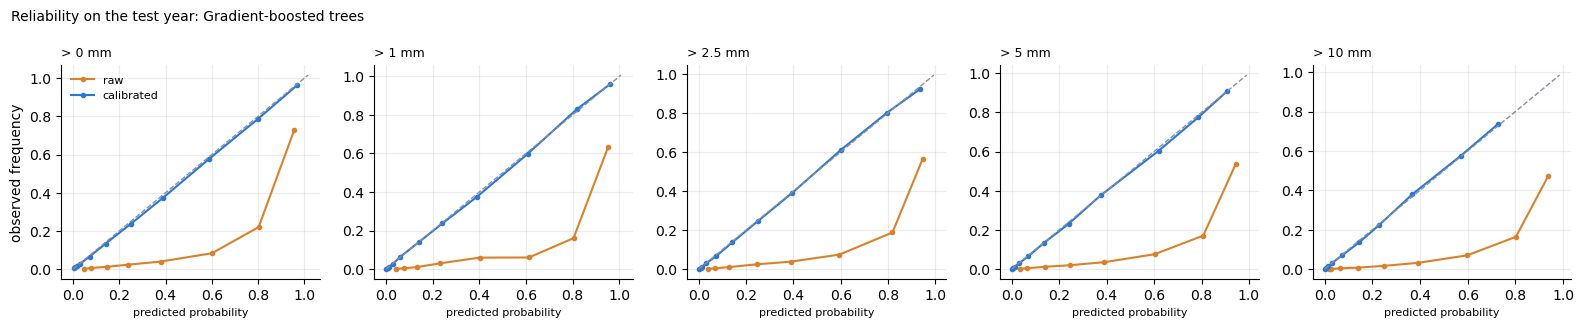

In [15]:
EDGES = [0, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 1.0001]
def reliability(df, col, t):
    b = F.col(col); expr = F.when(b < EDGES[1], 0)
    for i in range(1, len(EDGES) - 1): expr = expr.when(b < EDGES[i + 1], i)
    d = df.filter(F.col("thr") == t).withColumn("bin", expr.otherwise(len(EDGES) - 2))
    return d.groupBy("bin").agg(F.avg(col).alias("predicted"), F.avg("label").alias("observed"), F.count("*").alias("n")).orderBy("bin").toPandas()

vscore = {k: val_pr_auc(MODELS[k])["mean"] for k in MODELS}
best = max(vscore, key=vscore.get)
print("validation mean PR-AUC:", {NAMES[k]: round(v, 4) for k, v in vscore.items()}, "-> chosen:", NAMES[best])

fig, axes = plt.subplots(1, len(THRESHOLDS), figsize=(3.2 * len(THRESHOLDS), 3.3))
for ax, t in zip(axes, THRESHOLDS):
    for col, c, lab in [("p", ACCENT, "raw"), ("p_cal", BLUE, "calibrated")]:
        r = reliability(PRED[best], col, t); r = r[r["n"] >= 50]
        ax.plot(r["predicted"], r["observed"], marker="o", ms=3, color=c, label=lab)
    hi = max(0.05, float(ax.get_xlim()[1]), float(ax.get_ylim()[1]))
    ax.plot([0, hi], [0, hi], color=GREY, ls="--", lw=1); ax.set_title(f"> {t:g} mm", fontsize=9, loc="left"); ax.set_xlabel("predicted probability", fontsize=8)
axes[0].set_ylabel("observed frequency"); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"Reliability on the test year: {NAMES[best]}", fontsize=10, x=0.01, ha="left")
plt.tight_layout(); plt.savefig(f"{OUT}/reliability.png", dpi=160, bbox_inches="tight"); sync_up(); plt.show()

**What the plot shows**
- **Raw model (orange):** far below the diagonal. When it predicts 80%, rain happens only about 15 to 20% of the time. It over-predicts rain because of the class weights.
- **Calibrated model (blue):** almost exactly on the diagonal at every threshold. A predicted 20% means about 20%, and a predicted 60% means about 60%.
- **Fair test:** the calibration curves were fitted on 2023, and this plot is 2024, so the good fit isn't just the curves memorising the data.
- **Where it stops:** at more than 10 mm the blue line ends near 0.7, because the model rarely gives high probabilities for such rare, heavy rain.

### What the model uses

Feature importance tells you how much each feature contributed to the gradient-boosted model's predictions. A bigger number means the trees relied on that feature more, and the numbers add up to 1. I show the 15 largest.

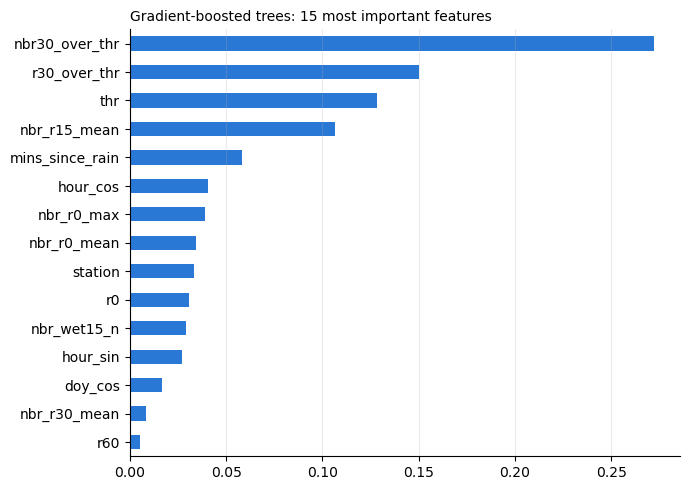

nbr30_over_thr     0.2721
r30_over_thr       0.1504
thr                0.1283
nbr_r15_mean       0.1065
mins_since_rain    0.0583
hour_cos           0.0403
nbr_r0_max         0.0392
nbr_r0_mean        0.0345
station            0.0334
r0                 0.0309
nbr_wet15_n        0.0293
hour_sin           0.0270
doy_cos            0.0168
nbr_r30_mean       0.0084
r60                0.0053
dtype: float64

In [16]:
gbt_clf = MODELS["gbt"].stages[-1]
imp_vals = gbt_clf.featureImportances.toArray()
imp = pd.Series(imp_vals, index=(["station"] + NUM)[:len(imp_vals)]).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 5))
imp.head(15)[::-1].plot.barh(ax=ax, color=BLUE); ax.set_title("Gradient-boosted trees: 15 most important features", fontsize=10, loc="left"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(f"{OUT}/feature_importance.png", dpi=160, bbox_inches="tight"); sync_up(); plt.show()
imp.round(4).head(15)

**The top features (importance):**
- `nbr30_over_thr` (0.27): the neighbours' average 30-minute rain compared with the threshold.
- `r30_over_thr` (0.15): the station's own 30-minute rain compared with the threshold.
- `thr` (0.13): the threshold itself, because the same weather makes "more than 1 mm" likely and "more than 10 mm" unlikely.
- `nbr_r15_mean` (0.11): the neighbours' average rain over the last 15 minutes.
- `mins_since_rain` (0.06): the minutes since the station last measured rain.
- After these come the time of day (`hour_cos`), then `nbr_r0_max` (one of my added features, seventh), the neighbours' latest reading, the station and `r0`.

**What this means**
- The four biggest features together make up about two thirds of the importance, so the model works mostly from how much rain is falling now, here and nearby, compared with the threshold.
- Neighbour features rank high. This fits with the caveat in 6.4: removing the `neighbours` group in the ablation didn't hurt, because the ratio `nbr30_over_thr` stayed in the model.
- The importance of correlated features gets split between them (for example `r30_over_thr` takes some of the importance that `r15` and `r30` would have), so a low number doesn't prove a feature is useless.
- This says what the model relies on, not what causes rain.

## 9. Asking the model a question

The task asks for a model that takes a station, a time and a threshold, and returns a probability. `predict_probability(station_id, time, threshold_mm)` does that.

**What it does, step by step**
- It rounds the time down to the nearest 5 minutes.
- It looks up that station's features at that time (recent rain, neighbours, hour and so on).
- It adds the threshold you asked for.
- It runs the chosen model (gradient-boosted trees) and gets a raw probability.
- It applies the calibration curve for that threshold, so the answer means what it says.

**Limits of the function**
- It needs a full last hour of trusted readings for that station. If there is a gap, it can't answer.
- Calibrated answers exist only for the five thresholds (0, 1, 2.5, 5, 10 mm). For any other threshold it still answers, but the probability is uncalibrated and the function says so.

In [17]:
def predict_probability(station_id, time, threshold_mm, model=None):
    model = model or best
    t = pd.Timestamp(time).floor("5min")
    row = feat.filter((F.col("station_id") == station_id) & (F.col("ts5") == F.lit(t.to_pydatetime()))).limit(1)
    if row.count() == 0:
        return None, "no complete last hour of trusted readings for this station at this time"
    d = (row.withColumn("thr", F.lit(float(threshold_mm))).withColumn("log_thr", F.log1p("thr"))
            .withColumn("r30_over_thr", F.col("r30") / (F.col("thr") + 0.2))
            .withColumn("nbr30_over_thr", F.col("nbr_r30_mean") / (F.col("thr") + 0.2))
            .withColumn("season", F.when(F.col("month").isin(12, 1, 2, 3), 1).when(F.col("month").isin(4, 5), 2)
                                   .when(F.col("month").isin(6, 7, 8, 9), 3).otherwise(4))
            .join(F.broadcast(clim_any), ["station_id", "hour", "season"], "left"))
    d = d.withColumn("clim_any", F.coalesce(F.col("clim_any"), F.lit(POS_RATE[THRESHOLDS[0]])))
    s = score(MODELS[model], d)
    p = s.first()["p"]
    if float(threshold_mm) in THRESHOLDS:
        p = CAL[(model, float(threshold_mm))].transform(VectorAssembler(inputCols=["p"], outputCol="pv").transform(s)).first()["p_cal"]
    return float(p), "calibrated" if float(threshold_mm) in THRESHOLDS else "uncalibrated (threshold not in the calibrated list)"

ex = feat.filter(F.col("year").isin(TEST_YEARS)).orderBy(F.rand(3)).limit(3).toPandas()
for r in ex.itertuples():
    for thr_ in (1.0, 5.0):
        p, note = predict_probability(r.station_id, r.ts5, thr_)
        print(f"{r.station_id} at {r.ts5}: P(more than {thr_:g} mm in the next 30 min) = {p:.3f} [{note}]  (actual: {r.y30:.1f} mm)")

S50 at 2024-07-05 00:55:00: P(more than 1 mm in the next 30 min) = 0.007 [calibrated]  (actual: 0.0 mm)


S50 at 2024-07-05 00:55:00: P(more than 5 mm in the next 30 min) = 0.003 [calibrated]  (actual: 0.0 mm)


S222 at 2024-02-19 07:25:00: P(more than 1 mm in the next 30 min) = 0.012 [calibrated]  (actual: 0.0 mm)


S222 at 2024-02-19 07:25:00: P(more than 5 mm in the next 30 min) = 0.005 [calibrated]  (actual: 0.0 mm)


S109 at 2024-04-27 12:40:00: P(more than 1 mm in the next 30 min) = 0.001 [calibrated]  (actual: 0.0 mm)


S109 at 2024-04-27 12:40:00: P(more than 5 mm in the next 30 min) = 0.000 [calibrated]  (actual: 0.0 mm)


I drew three random 2024 examples and asked for the 1 mm and 5 mm probabilities:

| Station and time | More than 1 mm | More than 5 mm | Actual rain |
|---|---|---|---|
| S50, 5 July 00:55 | 0.7% | 0.3% | 0.0 mm |
| S222, 19 February 07:25 | 1.2% | 0.5% | 0.0 mm |
| S109, 27 April 12:40 | 0.1% | 0.0% | 0.0 mm |

- All three were dry, and the model gave small probabilities, which is right.
- These examples are drawn at random with a fixed seed, so they are not hand-picked.
- Three dry cases prove nothing about rainy cases. The test tables in section 8 are the real evidence.

## 10. Conclusion

I built a model that gives the probability that a station collects more than 0, 1, 2.5, 5 or 10 mm in the next 30 minutes, from a station, a time and a threshold. It is evaluated on 2024, a year not used for training, tuning or calibration.

- **It works better than the simple rules.** The calibrated models beat both climatology and persistence on PR-AUC and on log loss at every threshold. At more than 1 mm the best model scores 0.63 PR-AUC, against 0.25 for persistence and 0.04 for climatology.
- **Best model:** gradient-boosted trees (depth 5, 60 rounds), chosen on the validation year. It had the lowest log loss and Brier score at every threshold. The three model types are close, so the choice matters less than the features and the calibration.
- **Calibration is what makes the probabilities usable.** Raw probabilities were worse than climatology because of the class weights. After isotonic calibration, skill versus climatology is about +0.43 to +0.50, and the reliability plot lies on the diagonal.
- **What drives the prediction:** recent rain at the station and at its neighbours, compared with the threshold. The station's own recent rain is the only feature group whose removal clearly hurts. My three added features gave a small gain, and `history_rate` did not help, so I dropped it.
- **Rarer rain is harder.** PR-AUC falls from about 0.73 at more than 0 mm to about 0.34 at more than 10 mm, but it stays far above the base rates of 6% and 0.4%.
- **Next steps:** train on more of the data (going from 1% to 5% helped a little), remove the dead sensors and faulty gauges found in my audit, and test on more than one year. These are listed in the limits below.

## 11. Limits

- **Real-time data is late.**
  - I treat each reading as available at its time stamp.
  - In real life, data arrives about 8 minutes later, so a live version would need to leave that gap before predicting.
- **Gaps in the data.**
  - The model uses only trusted readings.
  - It can't answer for a time after an outage, or for a station with a gap in the last hour.
- **Only a sample of the training data.**
  - The final models were trained on 5% of the training years, and tuning used a smaller part of that.
  - Going from 1% to 5% raised the best model's skill versus climatology from about 0.44 to 0.48 up to about 0.47 to 0.50, so more data would probably help a little more.
- **Cleaning is basic.**
  - I applied only two quality rules (outage days and partial station-days).
  - My separate audit found dead sensors, isolated spikes and a few faulty gauges, and these are not removed here.
- **One test year.**
  - Eight years is a short record, and 2024 is the only test year.
  - A different year, for example with a stronger monsoon, could give different scores.
- **The ablation understates neighbours.**
  - The neighbour ratio `nbr30_over_thr` sits in the threshold group, which was never removed.
  - So the ablation shows that the other neighbour features add little, not that neighbours don't matter.

## AI usage declaration
